# Single traj - EXP 8

In [21]:
import torch
import torch.nn.functional as F
import math
from pathlib import Path
import torch.nn as nn
from step.models import XResAttn
from fastai.vision.all import Learner, DataLoaders, L
from torch.nn  import L1Loss
import time

dvc = 'cuda' if torch.cuda.is_available() else 'cpu'


############ MODEL DEFINITION ############

class ResBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim), nn.GELU())
    def forward(self, x): return x + self.net(x)

class SingleTrajModel(nn.Module):
    """Frozen XResAttn + per-layer dual-attn pooling + log(T) → residual MLP head."""
    def __init__(self, backbone, dropout=0.0, freeze_backbone=True):
        super().__init__()
        self.backbone = backbone
        if freeze_backbone:
            self.backbone.requires_grad_(False)
        self.backbone.eval()
        self.drop = nn.Dropout(dropout)
        hidden_dim = backbone.encoder.layers[0].self_attn.embed_dim
        n_layers = len(backbone.encoder.layers)
        self.attn_queries = nn.ModuleList([
            nn.Linear(hidden_dim, 2, bias=False) for _ in range(n_layers)
        ])
        feat_dim = hidden_dim * n_layers * 3 + 1
        self.head = nn.Sequential(
                    nn.LayerNorm(feat_dim),
                    nn.Linear(feat_dim, 512),
                    nn.GELU(),
                    ResBlock(512),
                    nn.LayerNorm(512),
                    nn.Linear(512, 256),
                    nn.GELU(),
                    nn.Linear(256, 1)
                )

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()
        return self

    def forward(self, x):
        T = x.shape[1]
        with torch.no_grad():
            x = self.backbone.norm(x)
            x = self.backbone.convs(x.transpose(2, 1)).transpose(2, 1)  # (batch, T', hidden)
            src = self.backbone.pos_enc(x.transpose(1, 0))               # (T', batch, hidden)
            layer_outputs = []
            y = src
            for layer in self.backbone.encoder.layers:
                y = layer(y)
                layer_outputs.append(y.transpose(0, 1))   # (batch, T', hidden)
        # Dual attention pooling outside no_grad so attn_queries receive gradients
        layer_pools = []
        for i, z in enumerate(layer_outputs):
            scores = self.attn_queries[i](z)                        # (batch, T', 2)
            weights = F.softmax(scores, dim=1)                      # (batch, T', 2)
            layer_pools.append(z.mean(dim=1))                       # mean
            layer_pools.append((z * weights[:, :, 0:1]).sum(dim=1)) # attn head 1
            layer_pools.append((z * weights[:, :, 1:2]).sum(dim=1)) # attn head 2
        out = torch.cat(layer_pools, dim=1)
        out = self.drop(out)
        log_t = torch.full((out.shape[0], 1), math.log(T), device=out.device)
        out = torch.cat([out, log_t], dim=1)
        return self.head(out)
    

# Load Previous model
dim = 2
dls = DataLoaders.from_dsets([], []) # Empty train and validation datasets

# STEPalpha: Anomalous exponent model
model_alpha = XResAttn(dim, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
             block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
             dim_ff=512, nhead_enc=8, norm=False, linear_layers=[],yrange=(-0.1,2.1)).to('cuda')

# Create dummy learner
learn_alpha  = Learner(dls, model_alpha,  loss_func=L1Loss(), model_dir='')
# load the weights
model_alpha_path = Path('../xresattn_alpha_2d_varlen_relpolar_yrange_m01_21_big22E2')
model_alpha_name = model_alpha_path.name
learn_alpha.load(model_alpha_path)
learn_alpha.model.eval();

# Define single prediction model with frozen backbone
backbone_single = XResAttn(dim, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
dim_ff=512, nhead_enc=8, norm=False, linear_layers=[])

model_single = SingleTrajModel(backbone_single, dropout=0.1).to('cuda')

model_single.backbone.load_state_dict(learn_alpha.model.state_dict())

####### DATA PREPARATION ############
def get_angle(from_vec, # T, d=2
              to_vec,   # T, d=2
              ):
    x1, y1 = from_vec[...,0], from_vec[...,1]
    x2, y2 = to_vec[...,0], to_vec[...,1]
    dot = x1*x2 + y1*y2      # Dot product between [x1, y1] and [x2, y2]
    det = x1*y2 - y1*x2      # Determinant (cross2d) # 2.53 micros, njit 256 ns
    return np.arctan2(det, dot)

# We want a relative description of the trajectory
# the modulus of the displacement Delta r, and the change of angle between successive displacements Delta theta 
def cartesian_to_relative_polar(trajs_cart):
    """
    Converts 2D trajectories in cartesian coordinates to
    a relative representation of polar coordinates.

    Parameters:
    - cartesian_coordinates:
    A numpy array of shape (N, T, 2) where
    N is the number of trajectories,
    T is the number of time steps, and
    2 represents the x and y coordinates.

    Returns:
    - An array containing:
    the radius (rho) of each point, and
    the angle from previous direction (theta) of each point in radians.
    """
    # take displacements of the trajectory
    disps_cart = trajs_cart[:, 1:] - trajs_cart[:, :-1]
    # Allocate
    polar_coords = np.zeros_like(disps_cart)

    # Calculate the magnitude (rho) of each point
    polar_coords[...,0] = np.hypot(disps_cart[..., 0], disps_cart[..., 1])  #  dr

    # Calculate the angle (theta) between segments
    v1,v2 = trajs_cart[:,1:-1]-trajs_cart[:,:-2], trajs_cart[:,2:]-trajs_cart[:,1:-1]
    polar_coords[:,1:,1] = get_angle(v1,v2) # d theta

    return polar_coords

from collections import defaultdict
from torch.utils.data import Dataset, DataLoader, Sampler
import numpy as np

# --- Dataset ---------------------------------------------------------------
class TrajDataset(Dataset):
    """Pairs each polar trajectory (T, 2) with its scalar target."""
    def __init__(self, X, Y, idxs, augment=False):
        self.X = [X[i].squeeze(0) for i in idxs]   # list of (T, 2) tensors
        self.Y = Y[idxs]                             # (n,) tensor
        self.lengths = [x.shape[0] for x in self.X]
        self.augment = augment
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x = self.X[i]
        if self.augment and torch.rand(1).item() < 0.5:
            x = x.clone()
            x[:, 1] = -x[:, 1]  # mirror-reflect: flip delta-theta signs (preserves alpha)
        return x, self.Y[i:i+1]

# --- Bucket batch sampler --------------------------------------------------
class BucketBatchSampler(Sampler):
    """Yields batches where all trajectories share the same length."""
    def __init__(self, lengths, bs, shuffle=True):
        self.bs, self.shuffle = bs, shuffle
        buckets = defaultdict(list)
        for i, l in enumerate(lengths):
            buckets[l].append(i)
        self.buckets = list(buckets.values())

    def _make_batches(self):
        batches = []
        for bucket in self.buckets:
            idxs = list(bucket)
            if self.shuffle: np.random.shuffle(idxs)
            for j in range(0, len(idxs), self.bs):
                batches.append(idxs[j : j + self.bs])
        if self.shuffle: np.random.shuffle(batches)
        return batches

    def __iter__(self):
        yield from self._make_batches()

    def __len__(self):
        return sum(math.ceil(len(b) / self.bs) for b in self.buckets)

def collate_fn(batch):
    xs, ys = zip(*batch)
    return torch.stack(xs), torch.stack(ys)   # (bs, T, 2), (bs, 1)

## Generate the dataset
# Currently we are loading the dataset, but can be regenerated by setting load_dataset = False.
# ONLY DONE IF STRICTLY NECESSARY, as dataset generation is very costly.
from andi_datasets.datasets_challenge import challenge_theory_dataset

# X1, Y1, X2, Y2, X3, Y3 = challenge_theory_dataset(N = 100000, tasks = 1, dimensions = 2,
#                                         min_T = 10, max_T = 200, load_dataset = True)

# Prepare data in polar representation
# inputs = X1[1]
# outputs = torch.tensor(Y1[1]).to(dvc)

# tensor_X = []
# for i in inputs:
#     traj = torch.tensor(i).reshape(2, -1).T.unsqueeze(0)
#     traj += torch.randn_like(traj)*0.001 
#     tensor_X.append(traj)
# lengths = [t.shape[1] for t in tensor_X]
# polar_X = L([torch.tensor(cartesian_to_relative_polar(traj), dtype=torch.float).to(dvc) for traj in tensor_X])


# DataLoaders preparation
bs_train = 64
val_frac = 0.2
n = len(polar_X)
perm = np.random.permutation(n)
n_val = int(val_frac * n)
val_idxs, train_idxs = perm[:n_val], perm[n_val:]

train_ds = TrajDataset(polar_X, outputs, train_idxs, augment=True)
val_ds   = TrajDataset(polar_X, outputs, val_idxs,   augment=False)

train_dl = DataLoader(train_ds,
                      batch_sampler=BucketBatchSampler(train_ds.lengths, bs_train, shuffle=True),
                      collate_fn=collate_fn)
val_dl   = DataLoader(val_ds,
                      batch_sampler=BucketBatchSampler(val_ds.lengths,   bs_train, shuffle=False),
                      collate_fn=collate_fn)

dls_single = DataLoaders(train_dl, val_dl, device=dvc)



In [22]:
############### TRAINING #################

from fastai.callback.core import Callback, CancelFitException

class TimeLimitCallback(Callback):
    """Stop training after `max_seconds` seconds.
    FIXED TO 5 minutes, CANNOT BE CHANGED"""
    def __init__(self, max_seconds = 5*60): self.max_seconds = max_seconds
    def before_fit(self): self.start = time.time()
    def after_batch(self):
        if time.time() - self.start > self.max_seconds:
            raise CancelFitException()

model_single = SingleTrajModel(backbone_single, freeze_backbone=False).to('cuda')

# --- Learner ---------------------------------------------------------------
learn_single = Learner(dls_single, model_single, loss_func=L1Loss(), wd=1e-3)

LR_MAX = 1e-2
EPOCHS = 30


In [ ]:

learn_single.fit_one_cycle(EPOCHS, lr_max=LR_MAX)

epoch,train_loss,valid_loss,time
0,0.273458,0.275221,00:22
1,0.253103,0.256894,00:22
2,0.249619,0.246041,00:22
3,0.250522,0.242832,00:22
4,0.250189,0.245196,00:22
5,0.244655,0.244960,00:22
6,0.248284,0.245690,00:22
7,0.262808,0.262012,00:22
8,0.246645,0.249531,00:22
9,0.232360,0.240234,00:22


In [10]:
import matplotlib.pyplot as plt

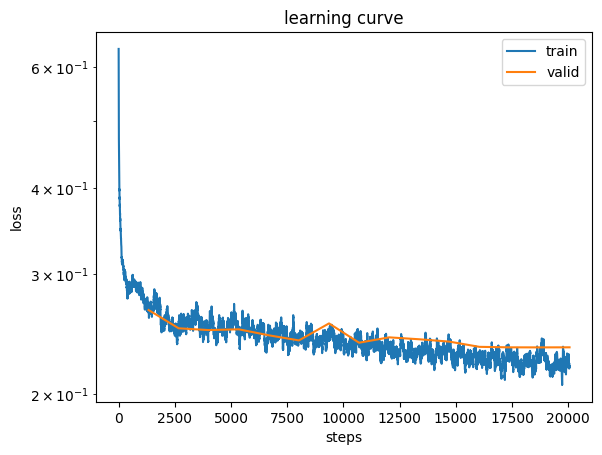

In [11]:
learn_single.recorder.plot_loss()
plt.yscale('log')

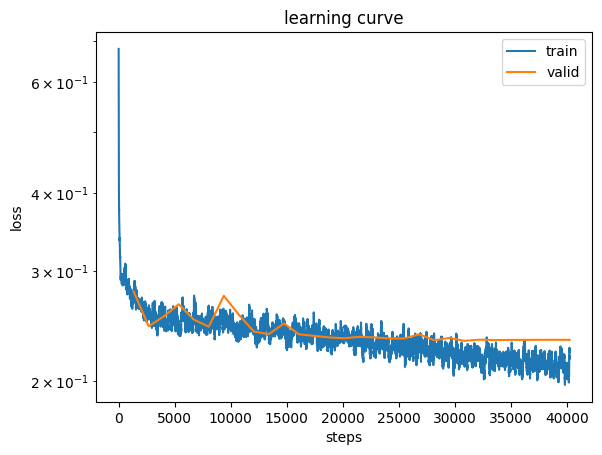

In [ ]:
learn_single.recorder.plot_loss()
plt.yscale('log')

In [12]:


####### EVALUATION #################
from prepare import evaluate
evaluate(learn_single, val_dl, 5, 20)

---
mae: 0.234116
mae_10_50:  0.300210
mae_50_100:  0.238847
mae_100_150:  0.209666
mae_150_200:  0.196622
total_seconds:    15.0
Non-backbone parameters: 3,559,427
